In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
from scipy.stats import multivariate_normal
import os
import sys

import matplotlib

import plotly.graph_objects as go

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

max_angle = 1000000 * np.pi / 180

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']
    phi_data=data['phi_data']

In [8]:
params = np.atleast_2d(ALPHAS)
params = np.atleast_2d([10., 10.])

logl, PHI, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=100
                                   )

PHI.shape

(1, 200, 100, 249)

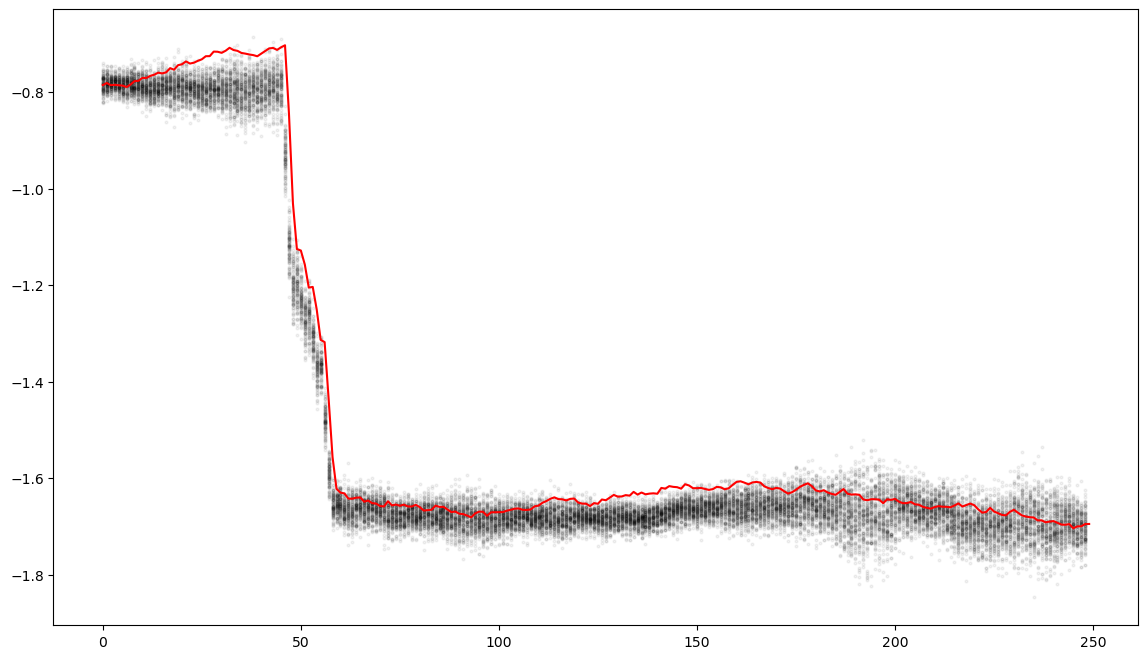

In [9]:
plt.figure(figsize=(14, 8))
data_idx = 0
phi_t = PHI[0, data_idx, :100, :]
plt.plot(phi_t.T, '.k', alpha=0.05, ms=4)
plt.plot(phi_data[data_idx, :], 'r')
plt.show()

# Variability

In [4]:
LOGLS = []
params = np.atleast_2d([10., 10.])
for i in tqdm(range(10)):
    logl, PHI, _ = calc_logl_core(x_data, y_data, dt,
                                    PE, DT, DR, FORCE_STRENGTH,
                                    params, torque_limit=max_angle,
                                    n_particles=100
                                    )
    LOGLS.append(logl)

LOGLS

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:03<00:00,  2.91it/s]


[array([178917.0062754126]),
 array([178928.2488284491]),
 array([178931.2518005394]),
 array([178906.7205587597]),
 array([178901.2595305715]),
 array([178900.1068402364]),
 array([178904.4505499788]),
 array([178904.4843036461]),
 array([178911.495678649]),
 array([178925.4375445638])]

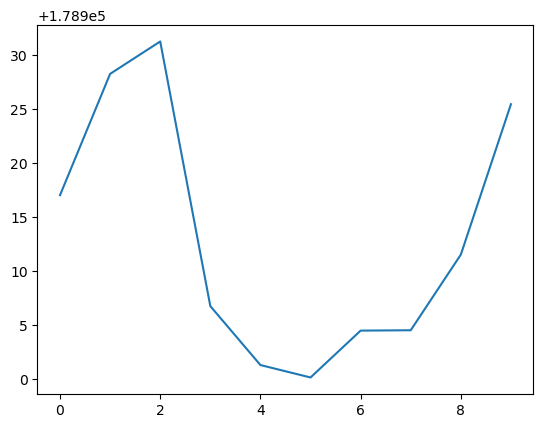

In [5]:
plt.plot(LOGLS)